# VaR & Expected Shortfall Engine with Full Backtesting

A VaR number is only useful if it can be trusted, and that trust comes from comparing each day's forecast with what actually happened. This notebook builds a small but complete market-risk engine with five methods and runs every one of them through seventeen years of the backtests a regulator or validator would apply.

**What it does.** It computes daily 99% VaR and 97.5% Expected Shortfall for a USD 100mm multi-asset portfolio with five methods, and backtests every one of them over 17 years with the tests a regulator or model validator would run.

**Data.** Daily total-return prices of eight U.S.-listed ETFs since 2007 (Yahoo Finance): U.S. large and small caps, international equities, Treasuries, investment-grade and high-yield credit, and gold.

**Methods.** Historical simulation, EWMA normal and Student-t (RiskMetrics), filtered historical simulation on a GJR-GARCH and a multivariate-t Monte Carlo.

VaR is backtested with the Kupiec, Christoffersen and Basel traffic-light tests and ES with the Acerbi–Székely test, alongside stressed VaR and Euler component VaR.

**Key output.** The model scorecard (exceptions, test p-values, traffic lights), VaR against P&L through 2008-style, 2020 and 2022 stress, today's VaR and ES by method and by asset, and a market-risk dashboard.

## 1. What the risk function has to show

A VaR number is only useful if it can be trusted, and trust comes from **backtesting**: comparing each day's forecast with the P&L that actually happened. Regulators formalised this (the Basel traffic light for VaR, and the FRTB move to 97.5% Expected Shortfall), and model validation teams run the same tests on every internal model.

This notebook is a small but complete market-risk engine:

1. **Five VaR/ES methods** that span the industry: from plain historical simulation to GARCH-filtered and Monte Carlo approaches.
2. **Daily out-of-sample forecasts since 2009**, each using only past data.
3. **The full test battery**: unconditional coverage (Kupiec), clustering of exceptions (Christoffersen), the Basel traffic light, and an ES backtest.
4. **Today's risk report**: VaR and ES by method, stressed VaR, and which assets drive the risk.

## 2. Methods and tests

With $R_t$ the portfolio's daily return and $\alpha$ the tail probability:

| Method | One-day VaR / ES |
|---|---|
| **Historical simulation (HS)** | empirical $\alpha$-quantile and tail mean of the last 500 days |
| **EWMA normal** | $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)R_{t-1}^2$, $\lambda=0.94$; $\text{VaR} = z_{\alpha}\sigma_t$, $\text{ES} = \sigma_t\,\varphi(z_{\alpha})/\alpha$ |
| **EWMA Student-t** | same $\sigma_t$, unit-variance $t_5$ quantiles, which fattens the tails |
| **FHS-GARCH** | GJR-GARCH(1,1) volatility forecast × empirical quantiles of its standardised residuals (Barone-Adesi et al.) |
| **Monte Carlo** | EWMA covariance of the eight assets, multivariate $t_5$ shocks, full non-linear portfolio revaluation |

**Backtests** on the exception indicator $I_t = \mathbb{1}[R_t < -\text{VaR}_t]$:

- **Kupiec POF:** is the exception rate equal to $\alpha$? $LR_{pof} \sim \chi^2_1$.
- **Christoffersen:** do exceptions cluster (an exception today makes one tomorrow more likely)? $LR_{ind} \sim \chi^2_1$; joint $LR_{cc} \sim \chi^2_2$.
- **Basel traffic light:** exceptions in the last 250 days. 0–4 green, 5–9 yellow, 10+ red.
- **Acerbi–Székely $Z_2$** for ES: $Z_2 = \sum_t \frac{R_t I_t}{T\alpha\,\text{ES}_t} + 1$, about 0 when ES is right and negative when ES is too small. Green above −0.70, red below −1.8 (their approximate 5% and 0.01% critical values).

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from arch import arch_model
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

PORTFOLIO_USD = 100_000_000
WEIGHTS = {
    "SPY": 0.30,
    "IWM": 0.10,
    "EFA": 0.10,
    "TLT": 0.15,
    "IEF": 0.10,
    "LQD": 0.10,
    "HYG": 0.10,
    "GLD": 0.05,
}
TICKERS = list(WEIGHTS)
START = "2007-01-01"
# look-back for HS and model estimation (about two years)
WINDOW = 500
GARCH_REFIT = 20  # refit the GARCH every 20 trading days
LAMBDA = 0.94  # RiskMetrics decay
NU = 5  # Student-t degrees of freedom
N_SIMS = 5_000  # Monte Carlo scenarios per day
VAR_Q, ES_Q = 0.01, 0.025  # 99% VaR, 97.5% ES
SEED = 3

print(f"yfinance {yf.__version__} · arch · run on {dt.date.today():%Y-%m-%d}")

yfinance 1.7.0 · arch · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "Historical sim": PALETTE[0],
    "EWMA normal": PALETTE[1],
    "EWMA t": PALETTE[2],
    "FHS-GARCH": PALETTE[6],
    "Monte Carlo t": PALETTE[3],
}

## 4. Data

Total-return (dividend-adjusted) closes from Yahoo Finance. The portfolio is rebalanced daily to fixed weights, so its daily return is $R_t = \sum_i w_i\,(e^{r_{i,t}} - 1)$, with $r_{i,t}$ the log return of asset $i$.

| Ticker | Asset | Weight |
|---|---|---|
| SPY | US large caps | 30% |
| IWM | US small caps | 10% |
| EFA | International developed equities | 10% |
| TLT | 20+ year Treasuries | 15% |
| IEF | 7–10 year Treasuries | 10% |
| LQD | Investment-grade corporates | 10% |
| HYG | High-yield corporates | 10% |
| GLD | Gold | 5% |

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    if isinstance(px, pd.Series):
        px = px.to_frame(TICKERS[0])
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
# completed sessions only (no intraday row)
prices = prices[prices.index < pd.Timestamp.today().normalize()]
prices = prices.dropna(how="all").ffill(limit=3)

# --- Data cleaning: one-day bad prints that reverse the next day are replaced
# by interpolation
raw_ret = np.log(prices).diff()
# robust daily sigma
scale = raw_ret.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw_ret.abs() > 10 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
# A genuine crash-and-rebound (e.g. 12-13 Mar 2020) moves many assets at once;
# a bad print is idiosyncratic.
market_wide = (raw_ret.abs() > 4 * scale).sum(axis=1) >= 3
spike = (
    spike & ~market_wide.values[:, None]
    if prices.shape[1] >= 3
    else spike & False
)
for c in prices.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = np.log(prices).diff().dropna()
EVAL_DATE = returns.index.max()
print(
    f"{len(returns):,} trading days · {returns.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · {', '.join(prices.columns)}"
)

4,911 trading days · 2007-04-12 → 2026-10-16 · SPY, IWM, EFA, TLT, IEF, LQD, HYG, GLD


In [4]:
w = pd.Series(WEIGHTS)[returns.columns].values
simple = np.expm1(returns)
# daily portfolio return (decimal)
port = (simple @ w).rename("portfolio")
pnl = port * PORTFOLIO_USD
print(
    f"Portfolio: annual vol {port.std() * np.sqrt(252):.1%} · worst day"
    f" {port.min():.2%} ({port.idxmin():%Y-%m-%d}) · best day"
    f" {port.max():.2%} · excess kurtosis {port.kurt():.1f}"
)
returns.describe().T[["mean", "std", "min", "max"]].assign(
    ann_vol=lambda d: d["std"] * np.sqrt(252)
).round(4)

Portfolio: annual vol 11.0% · worst day -6.05% (2020-03-12) · best day 8.25% · excess kurtosis 13.6


,mean,std,min,max,ann_vol
SPY,0.00,0.01,-0.12,0.14,0.20
IWM,0.00,0.02,-0.14,0.09,0.25
EFA,0.00,0.01,-0.12,0.15,0.22
TLT,0.00,0.01,-0.07,0.07,0.15
IEF,0.00,0.00,-0.03,0.03,0.07
LQD,0.00,0.01,-0.10,0.09,0.09
HYG,0.00,0.01,-0.08,0.12,0.11
GLD,0.00,0.01,-0.11,0.11,0.18


## 5. Rolling forecasts, out of sample

Every forecast for day $t$ uses only returns up to $t-1$. The first `WINDOW` days are the warm-up.

In [5]:
T = len(port)
R = port.values
idx = port.index
out = {
    m: pd.DataFrame(
        index=idx[WINDOW:], columns=["VaR", "VaR97.5", "ES"], dtype=float
    )
    for m in MODEL_COLORS
}
z99, z975 = stats.norm.ppf(VAR_Q), stats.norm.ppf(ES_Q)
t_scale = np.sqrt((NU - 2) / NU)  # unit-variance Student-t
t99, t975 = stats.t.ppf(VAR_Q, NU) * t_scale, stats.t.ppf(ES_Q, NU) * t_scale
t_es = (
    t_scale
    * stats.t.pdf(stats.t.ppf(ES_Q, NU), NU)
    / ES_Q
    * (NU + stats.t.ppf(ES_Q, NU) ** 2)
    / (NU - 1)
)


def tail(x, q):
    """VaR (positive number) and the mean loss beyond the q-quantile."""
    v = np.quantile(x, q)
    return -v, -x[x <= v].mean()


# --- 1. Historical simulation
hs = np.full((T - WINDOW, 3), np.nan)
for k, t in enumerate(range(WINDOW, T)):
    win = R[t - WINDOW : t]
    v99, _ = tail(win, VAR_Q)
    v975, es = tail(win, ES_Q)
    hs[k] = [v99, v975, es]
out["Historical sim"][:] = hs

# --- 2/3. EWMA normal and Student-t
sig2 = np.empty(T)
sig2[0] = R[:WINDOW].var()
for t in range(1, T):
    sig2[t] = LAMBDA * sig2[t - 1] + (1 - LAMBDA) * R[t - 1] ** 2
sig = np.sqrt(sig2[WINDOW:])
out["EWMA normal"][:] = np.c_[
    -z99 * sig, -z975 * sig, sig * stats.norm.pdf(z975) / ES_Q
]
out["EWMA t"][:] = np.c_[-t99 * sig, -t975 * sig, t_es * sig]
print("HS and EWMA done")

HS and EWMA done


In [6]:
# --- 4. Filtered historical simulation on a GJR-GARCH(1,1)
fhs = np.full((T - WINDOW, 3), np.nan)
for start in range(WINDOW, T, GARCH_REFIT):
    fit = arch_model(
        R[start - WINDOW : start] * 100,
        mean="Constant",
        vol="GARCH",
        p=1,
        o=1,
        q=1,
        dist="t",
    ).fit(disp="off")
    mu, om, a, g, b = (
        fit.params[k]
        for k in ["mu", "omega", "alpha[1]", "gamma[1]", "beta[1]"]
    )
    z = fit.std_resid[~np.isnan(fit.std_resid)]
    s2 = fit.conditional_volatility[-1] ** 2
    e_prev = R[start - 1] * 100 - mu
    for t in range(start, min(start + GARCH_REFIT, T)):
        # one-step-ahead variance for day t
        s2 = om + (a + g * (e_prev < 0)) * e_prev**2 + b * s2
        sims = (mu + np.sqrt(s2) * z) / 100
        v99, _ = tail(sims, VAR_Q)
        v975, es = tail(sims, ES_Q)
        fhs[t - WINDOW] = [v99, v975, es]
        # becomes known after the close
        e_prev = R[t] * 100 - mu
out["FHS-GARCH"][:] = fhs

# --- 5. Monte Carlo: EWMA covariance, multivariate t, full revaluation
rng = np.random.default_rng(SEED)
X = returns.values
cov = np.cov(X[:WINDOW].T)
mc = np.full((T - WINDOW, 3), np.nan)
for t in range(1, T):
    cov = LAMBDA * cov + (1 - LAMBDA) * np.outer(X[t - 1], X[t - 1])
    if t >= WINDOW:
        L = np.linalg.cholesky(cov + 1e-12 * np.eye(len(w)))
        shocks = (
            rng.standard_normal((N_SIMS, len(w)))
            / np.sqrt(rng.chisquare(NU, (N_SIMS, 1)) / NU)
            * t_scale
        )
        sims = np.expm1(shocks @ L.T) @ w
        v99, _ = tail(sims, VAR_Q)
        v975, es = tail(sims, ES_Q)
        mc[t - WINDOW] = [v99, v975, es]
out["Monte Carlo t"][:] = mc
print("FHS-GARCH and Monte Carlo done")

FHS-GARCH and Monte Carlo done


## 6. Backtesting

In [7]:
def kupiec(x, n, p):
    """Proportion-of-failures LR test; returns statistic and p-value."""
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        ph = x / n
        lr = -2 * (
            (n - x) * np.log(1 - p)
            + x * np.log(p)
            - (n - x) * np.log(1 - ph)
            - x * np.log(ph)
        )
    return lr, 1 - stats.chi2.cdf(lr, 1)


def christoffersen(I):
    """Independence LR test on the exception sequence."""
    I = I.astype(int)
    n00 = np.sum((I[:-1] == 0) & (I[1:] == 0))
    n01 = np.sum((I[:-1] == 0) & (I[1:] == 1))
    n10 = np.sum((I[:-1] == 1) & (I[1:] == 0))
    n11 = np.sum((I[:-1] == 1) & (I[1:] == 1))
    p01, p11 = n01 / max(n00 + n01, 1), n11 / max(n10 + n11, 1)
    p = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    ll = lambda q, a, b: (a * np.log(1 - q) if a else 0) + (
        b * np.log(q) if b and q > 0 else 0
    )
    lr = -2 * (
        ll(p, n00 + n10, n01 + n11) - ll(p01, n00, n01) - ll(p11, n10, n11)
    )
    return lr, 1 - stats.chi2.cdf(lr, 1)


realised = port.loc[out["Historical sim"].index]
rows, exc = [], {}
for m, f in out.items():
    I = (realised < -f["VaR"]).values
    exc[m] = pd.Series(I, index=f.index)
    x, n = I.sum(), len(I)
    lr_pof, p_pof = kupiec(x, n, VAR_Q)
    lr_ind, p_ind = christoffersen(I)
    p_cc = 1 - stats.chi2.cdf(lr_pof + lr_ind, 2)
    rolling = pd.Series(I, index=f.index).rolling(250).sum()
    zone = (
        pd.cut(
            rolling.dropna(),
            [-1, 4, 9, 250],
            labels=["green", "yellow", "red"],
        ).value_counts(normalize=True)
        * 100
    )
    I975 = (realised < -f["VaR97.5"]).values
    z2 = (
        np.sum(realised.values * I975 / (len(I975) * ES_Q * f["ES"].values))
        + 1
    )
    rows.append({
        "model": m,
        "exceptions": x,
        "expected": n * VAR_Q,
        "rate %": x / n * 100,
        "Kupiec p": p_pof,
        "Christoffersen p": p_ind,
        "cond. coverage p": p_cc,
        "Basel zone now": (
            "🟢 green"
            if rolling.iloc[-1] <= 4
            else ("🟡 yellow" if rolling.iloc[-1] <= 9 else "🔴 red")
        ),
        "% days green": zone.get("green", 0),
        "% days red": zone.get("red", 0),
        "ES Z2": z2,
        "ES verdict": "🟢" if z2 > -0.70 else ("🟡" if z2 > -1.8 else "🔴"),
        "avg VaR $mm": f["VaR"].mean() * PORTFOLIO_USD / 1e6,
    })
scorecard = pd.DataFrame(rows).set_index("model")
scorecard.round(3)

,exceptions,expected,rate %,Kupiec p,Christoffersen p,cond. coverage p,Basel zone now,% days green,% days red,ES Z2,ES verdict,avg VaR $mm
model,,,,,,,,,,,,
Historical sim,46,44.11,1.04,0.78,0.00,0.00,🟢 green,79.60,4.18,-0.10,🟢,1.76
EWMA normal,88,44.11,2.00,0.00,0.00,0.00,🟡 yellow,37.79,4.61,-0.60,🟢,1.29
EWMA t,65,44.11,1.47,0.00,0.00,0.00,🟢 green,66.80,1.85,-0.35,🟢,1.45
FHS-GARCH,52,44.11,1.18,0.25,0.15,0.18,🟢 green,84.31,0.00,-0.09,🟢,1.44
Monte Carlo t,67,44.11,1.52,0.00,0.00,0.00,🟢 green,70.45,1.85,-0.39,🟢,1.42


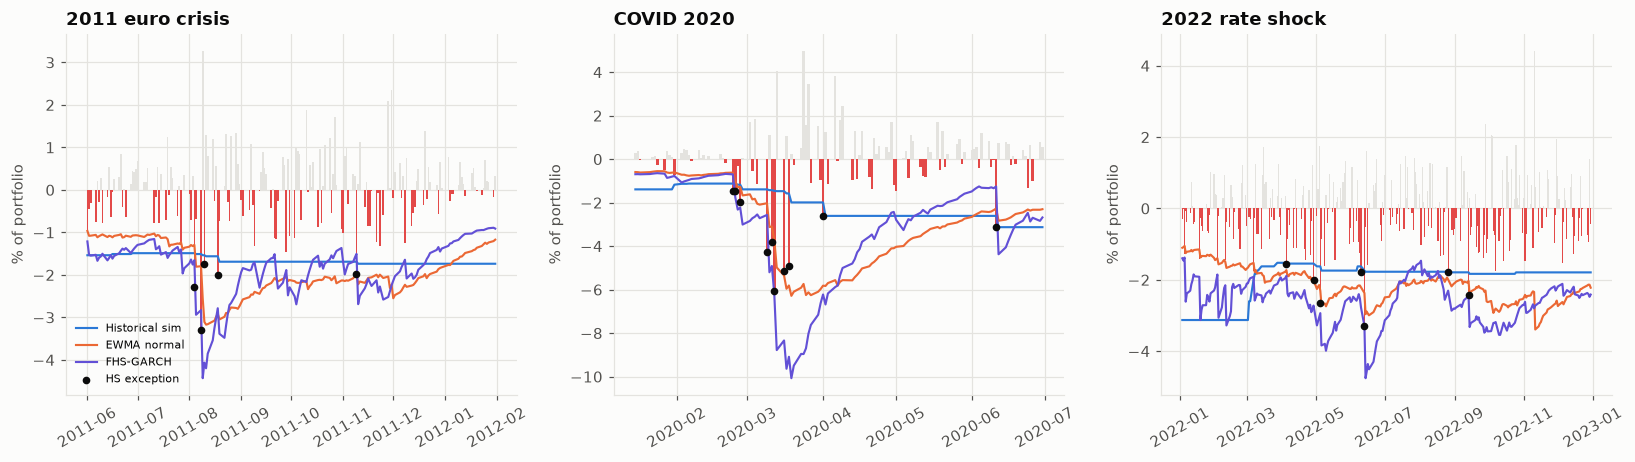

In [8]:
# --- Chart 1: VaR vs realised P&L through three stress episodes
episodes = {
    "2011 euro crisis": ("2011-06-01", "2012-01-31"),
    "COVID 2020": ("2020-01-15", "2020-06-30"),
    "2022 rate shock": ("2022-01-01", "2022-12-31"),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=False)
for ax, (name, (a, b)) in zip(axes, episodes.items()):
    r = realised.loc[a:b] * 100
    ax.bar(
        r.index,
        r.values,
        color=[STATUS["red"] if v < 0 else GRID for v in r.values],
        width=1.0,
    )
    for m in ["Historical sim", "EWMA normal", "FHS-GARCH"]:
        ax.plot(
            r.index,
            -out[m].loc[a:b, "VaR"] * 100,
            color=MODEL_COLORS[m],
            lw=1.4,
            label=m,
        )
    hs_exc = exc["Historical sim"].loc[a:b]
    ax.scatter(
        r.index[hs_exc.values],
        r.values[hs_exc.values],
        s=16,
        color=INK,
        zorder=3,
        label="HS exception",
    )
    ax.set_title(name)
    ax.set_ylabel("% of portfolio")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout()
save_fig(fig, "01_var_vs_pnl_stress")
plt.show()

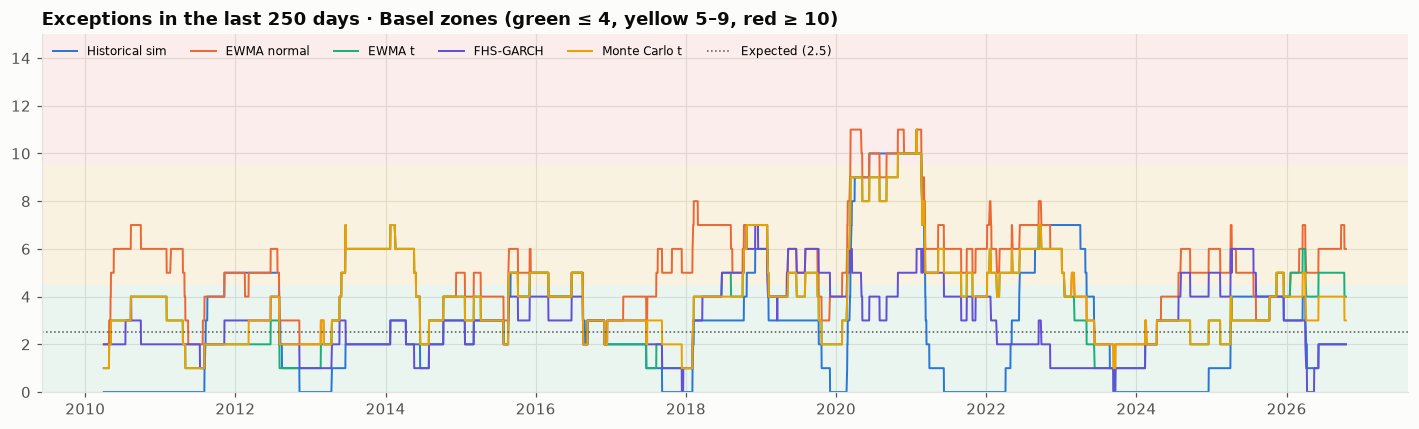

In [9]:
# --- Chart 2: rolling 250-day exception counts against the Basel zones
fig, ax = plt.subplots(figsize=(13, 4))
ax.axhspan(0, 4.5, color=STATUS["green"], alpha=0.08, lw=0)
ax.axhspan(4.5, 9.5, color=STATUS["amber"], alpha=0.10, lw=0)
ax.axhspan(9.5, 30, color=STATUS["red"], alpha=0.08, lw=0)
for m, I in exc.items():
    ax.plot(
        I.index, I.rolling(250).sum(), color=MODEL_COLORS[m], lw=1.3, label=m
    )
ax.axhline(2.5, color=INK_2, ls=":", lw=1, label="Expected (2.5)")
ax.set_ylim(
    0, max(15, max(I.rolling(250).sum().max() for I in exc.values()) + 1)
)
ax.set_title(
    "Exceptions in the last 250 days · Basel zones (green ≤ 4, yellow 5–9, red"
    " ≥ 10)"
)
ax.legend(ncol=6, fontsize=8, loc="upper left")
plt.tight_layout()
save_fig(fig, "02_basel_traffic_light")
plt.show()

## 7. Today's risk report

### 7.1 VaR and ES by method, and stressed VaR

Basel 2.5 adds a **stressed VaR**: the same portfolio valued with returns from a one-year period of significant stress. We take the 250 days that would have hurt today's portfolio most, which is the 2008 crisis for this mix.

In [10]:
today = (
    pd.DataFrame({m: f.iloc[-1] for m, f in out.items()}).T
    * PORTFOLIO_USD
    / 1e6
)
today = today.rename(
    columns={
        "VaR": "VaR 99% ($mm)",
        "VaR97.5": "VaR 97.5% ($mm)",
        "ES": "ES 97.5% ($mm)",
    }
)

# Stressed VaR: worst 250-day window for today's weights (historical simulation
# inside the window)
roll_loss = port.rolling(250).apply(lambda x: -np.quantile(x, VAR_Q), raw=True)
s_end = roll_loss.idxmax()
s_window = port.loc[:s_end].iloc[-250:]
svar, ses = tail(s_window.values, VAR_Q)[0], tail(s_window.values, ES_Q)[1]
today.loc["Stressed HS (Basel 2.5)"] = [
    svar * PORTFOLIO_USD / 1e6,
    np.nan,
    ses * PORTFOLIO_USD / 1e6,
]
print(f"Stress window: {s_window.index[0]:%Y-%m-%d} → {s_end:%Y-%m-%d}")
today.round(2)

Stress window: 2019-03-22 → 2020-03-18


,VaR 99% ($mm),VaR 97.5% ($mm),ES 97.5% ($mm)
Historical sim,1.70,1.17,1.74
EWMA normal,1.12,0.94,1.12
EWMA t,1.25,0.96,1.31
FHS-GARCH,1.28,1.03,1.41
Monte Carlo t,1.22,0.94,1.28
Stressed HS (Basel 2.5),4.58,NaN,3.95


### 7.2 Which assets drive the risk? Euler component VaR

With today's EWMA covariance $\Sigma$, parametric VaR is $z\sqrt{w^\top\Sigma w}$ and it splits exactly into contributions $w_i(\Sigma w)_i / \sqrt{w^\top\Sigma w} \times z$. A component can be negative: that asset hedges the others.

In [11]:
sig_p = np.sqrt(w @ cov @ w)
component = w * (cov @ w) / sig_p * (-z99) * PORTFOLIO_USD / 1e6
comp = pd.DataFrame(
    {
        "weight %": w * 100,
        "stand-alone VaR $mm": (
            -z99 * np.sqrt(np.diag(cov)) * w * PORTFOLIO_USD / 1e6
        ),
        "component VaR $mm": component,
    },
    index=returns.columns,
)
comp["share of VaR %"] = (
    comp["component VaR $mm"] / comp["component VaR $mm"].sum() * 100
)
comp.loc["Total"] = [
    100,
    comp["stand-alone VaR $mm"].sum(),
    comp["component VaR $mm"].sum(),
    100,
]
print(
    "Diversification benefit:"
    f" {1 - comp.loc['Total', 'component VaR $mm'] / comp.loc['Total', 'stand-alone VaR $mm']:.0%}"
)
comp.round(3)

Diversification benefit: 22%


,weight %,stand-alone VaR $mm,component VaR $mm,share of VaR %
SPY,30.00,0.42,0.35,31.03
IWM,10.00,0.21,0.17,15.37
EFA,10.00,0.17,0.15,13.10
TLT,15.00,0.24,0.15,13.82
IEF,10.00,0.08,0.06,5.42
LQD,10.00,0.09,0.07,6.32
HYG,10.00,0.06,0.05,4.50
GLD,5.00,0.16,0.12,10.45
Total,100.00,1.43,1.12,100.00


## 8. Market-risk dashboard

In [12]:
last3 = realised.index[
    realised.index >= EVAL_DATE - pd.Timedelta(days=3 * 365)
]
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.1,
    specs=[[{"colspan": 2}, None], [{}, {"type": "table"}]],
    row_heights=[0.48, 0.52],
    subplot_titles=(
        "Daily P&L vs 99% VaR, last three years ($mm)",
        "Component VaR today ($mm)",
        "Model scorecard (since 2009)",
    ),
)
dash.add_trace(
    go.Bar(
        x=last3,
        y=realised.loc[last3] * PORTFOLIO_USD / 1e6,
        name="P&L",
        marker_color=[
            STATUS["red"] if v < 0 else "#c9c8c3" for v in realised.loc[last3]
        ],
    ),
    1,
    1,
)
for m in ["Historical sim", "FHS-GARCH", "EWMA t"]:
    dash.add_trace(
        go.Scatter(
            x=last3,
            y=-out[m].loc[last3, "VaR"] * PORTFOLIO_USD / 1e6,
            name=f"VaR · {m}",
            line=dict(color=MODEL_COLORS[m], width=1.6),
        ),
        1,
        1,
    )
c = comp.drop("Total")
dash.add_trace(
    go.Bar(
        x=c.index,
        y=c["component VaR $mm"],
        marker_color=[
            PALETTE[0] if v >= 0 else PALETTE[2]
            for v in c["component VaR $mm"]
        ],
        showlegend=False,
        name="Component VaR",
    ),
    2,
    1,
)
sc = scorecard
dash.add_trace(
    go.Table(
        header=dict(
            values=[
                "Model",
                "Exc. / exp.",
                "Kupiec p",
                "Christ. p",
                "Basel now",
                "ES Z2",
                "VaR today $mm",
                "ES today $mm",
            ],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[
                sc.index,
                [
                    f"{e} / {x:.0f}"
                    for e, x in zip(sc["exceptions"], sc["expected"])
                ],
                sc["Kupiec p"].round(3),
                sc["Christoffersen p"].round(3),
                sc["Basel zone now"],
                [
                    f"{v} {z:.2f}"
                    for v, z in zip(sc["ES verdict"], sc["ES Z2"])
                ],
                today.loc[sc.index, "VaR 99% ($mm)"].round(2),
                today.loc[sc.index, "ES 97.5% ($mm)"].round(2),
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
            height=26,
        ),
    ),
    2,
    2,
)
best = scorecard["cond. coverage p"].idxmax()
dash.update_layout(
    height=900,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=1.06, x=0),
    bargap=0,
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            "<b>Market risk · USD 100mm multi-asset portfolio ·"
            f" {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>99% VaR (FHS-GARCH)"
            f" ${today.loc['FHS-GARCH', 'VaR 99% ($mm)']:.2f}mm · 97.5% ES"
            f" ${today.loc['FHS-GARCH', 'ES 97.5% ($mm)']:.2f}mm · stressed"
            f" VaR ${svar * PORTFOLIO_USD / 1e6:.2f}mm · best-calibrated"
            f" model: {best}</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")

scorecard.to_csv(OUT_DIR / "backtest_scorecard.csv")
today.to_csv(OUT_DIR / "var_es_today.csv")
pd.concat({m: f for m, f in out.items()}, axis=1).to_csv(
    OUT_DIR / "daily_var_es_forecasts.csv"
)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**What the backtests say**

**Historical simulation gets the count right and the timing wrong.** Its exception rate is almost exactly 1%, but the exceptions come in clusters: the Christoffersen test rejects independence. With equal weight on two years of history, HS under-forecasts right after volatility jumps (March 2020) and over-forecasts long after the storm. Its average VaR is also the highest of all models, so it is expensive in capital *and* late.

- **EWMA normal adapts fast but has thin tails.** It has about twice the expected exceptions, spends most of the time outside the Basel green zone, and its ES statistic is the closest to the warning threshold. A normal tail is far too short for a portfolio with an excess kurtosis above 10.
- **Fat tails alone are not enough.** EWMA-t and the multivariate-t Monte Carlo cut the exceptions but still sit around 1.5%, and still cluster: the 0.94 decay reacts, but not as fast as volatility does in a crash.
- **FHS-GARCH is the only model that passes every test.** Coverage (Kupiec), independence (Christoffersen), the joint test and the ES test all pass, and it never reached the Basel red zone. The asymmetric GJR filter raises volatility faster after losses, and the empirical residuals supply the fat tails. This is why filtered historical simulation is the industry's workhorse.
- **Stressed VaR is about three and a half times today's VaR**: the 2008 window shows what this portfolio would lose in a year like the GFC.
- **Equities drive the risk.** SPY, IWM and EFA are 50% of the weight but about 60% of the VaR; gold and Treasuries contribute less than their weight. The diversification benefit is about 22%.

**Limitations**

- **One-day horizon, no liquidity horizons.** FRTB scales ES by liquidity horizons per risk factor, and market liquidity is not modelled here.
- **ETF proxies** of real positions; total-return prices include dividends.
- **The Z2 thresholds** are the approximate critical values from Acerbi and Székely (2014); a production test would simulate them under each model.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (1996). *Supervisory framework for the use of "backtesting" in conjunction with the internal models approach to market risk capital requirements*. Bank for International Settlements. https://www.bis.org/publ/bcbs22.htm
- Basel Committee on Banking Supervision. (2019). *Minimum capital requirements for market risk*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d457.htm
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review, 39*(4), 841–862. https://doi.org/10.2307/2527341
- Barone-Adesi, G., Giannopoulos, K., & Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets, 19*(5), 583–602. https://doi.org/10.1002/(SICI)1096-9934(199908)19:5<583::AID-FUT5>3.0.CO;2-S
- Artzner, P., Delbaen, F., Eber, J.-M., & Heath, D. (1999). Coherent measures of risk. *Mathematical Finance, 9*(3), 203–228. https://doi.org/10.1111/1467-9965.00068

### Machine learning and deep learning

- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall. https://doi.org/10.1201/9780429246593